In [3]:
import sys
sys.path.append("../")

from config import *
from figs_config import *

from interpmodules import helpers

Loaded aesthetics module


In [1]:
# Models

from interpmodules import helpers
import skgstat as skg
skgstat_mdls = {'spherical': skg.models.spherical, 
                'exponential': skg.models.exponential,
                'gaussian': skg.models.gaussian,
                'cubic': skg.models.cubic,
                'stable': skg.models.stable,
                'matern': skg.models.matern,
               'hole': helpers.hole}

In [4]:
# set up data
import joblib
import pandas as pd

src_pvdata = joblib.load( projdir + '/data/fsLR-4k_reduced-midthickness_neuromaps.pkl')

maptags = pd.read_table(projdir + '/data/surf_map_names', delimiter = " ", dtype = str)
maptags = list(maptags.columns)


In [5]:
Dist = helpers.internal_distance_matrix(src_pvdata.points, 'euclidean')

In [7]:
import joblib
mapnames, h, all_ev = joblib.load( '/home/yzhou/gitrepo/interpolate/results/stats/neuromaps_collected_expvgm.pkl' )

In [18]:
import numpy as np
# starting point for parameter values

def init_parameters(mapvals, Dist, h, ev):

    nh = len(h)
    p0 = {
          3: [np.max(h), np.nanmax(ev), np.nanmax(ev)/nh],
          4: [np.max(h), np.nanmax(ev), np.nanmax(ev)/nh, ev[0]]
         }
    # upper bound lower bound
    bounds = {3: ([0.00001]*3, [np.max(Dist), semivariance(np.nanmax(mapvals), np.nanmin(mapvals)),
                        semivariance(np.nanmax(mapvals), np.nanmin(mapvals))]),
    4: ([0.00001]*4, [np.max(Dist), semivariance(np.nanmax(mapvals), np.nanmin(mapvals)),
                        semivariance(np.nanmax(mapvals), np.nanmin(mapvals)), 100])}

    return p0, bounds

In [20]:
def semivariance(y1, y2):
    return .5 * (y1 - y2)**2

In [23]:
model_scores = {}


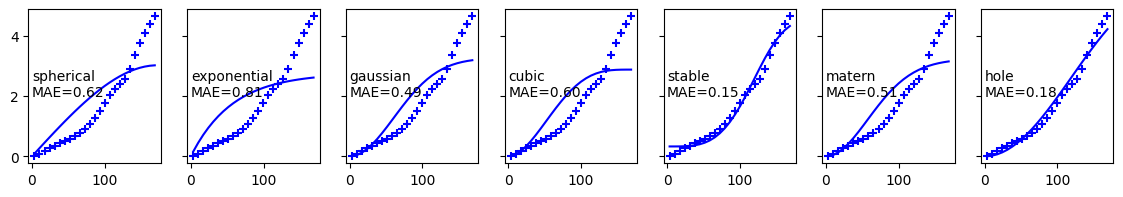

In [133]:
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from sklearn.metrics import r2_score
from interpmodules import metrics
from scipy.stats import zscore

# Fitting
mi=0
mapname=mapnames[mi]
mapvals = src_pvdata[mapname]

Cof = {}
Cov = {}
gof = {}

fig, axs = plt.subplots(1, len(skgstat_mdls), figsize = (14,2), sharey=True)

ev = all_ev[:,mi]


for ind, model in enumerate(skgstat_mdls):

    

    p0, bounds = init_parameters(mapvals, Dist, h, ev)
    
    axs[ind].scatter(h, ev, marker = "+", color = 'b')

    cof = None; cov = None
    
    if model in ['stable', 'matern']:
        cof, cov = curve_fit(skgstat_mdls[model], h, ev, method = 'trf', p0 = p0[4], bounds = bounds[4], maxfev=1000)
    
    else:
        cof, cov = curve_fit(skgstat_mdls[model], h, ev, method = 'trf', p0 = p0[3], bounds = bounds[3], maxfev=1000)

    Cof[model] = cof
    Cov[model] = cov
    
    v_pred = skgstat_mdls[model](h, *cof)
    x_s = np.linspace(h.min(), h.max())
    axs[ind].plot(h, v_pred, color = 'b')
    mae = np.mean(metrics.metric(v_pred, ev, 'residual'))
    r2 = r2_score(ev, v_pred, force_finite=False)
    gof[model] = r2
    
    axs[ind].text(x=0, y=2,s= model + "\n" + r'MAE=' + '{0:.2f}'.format(mae))

model_scores[mapname] = gof

In [134]:
best_model_name = pd.DataFrame(model_scores).sort_values(by=mapname).index[-1]

In [135]:
Cof[best_model_name]

array([172.1622173 ,   4.26925207,   3.83761733,   0.32933829])

In [136]:
import joblib

kc,kv,uc, uv = joblib.load(projdir + "/data/sampling/fsLR-4k_reduced-midthickness_samp-dsk33_pct-25_iters-100.pkl")[1]

In [137]:
mdl

array([0.3293422 , 0.32960044, 0.3311994 , 0.33610375, 0.34706351,
       0.36753214, 0.40155958, 0.45363635, 0.52846868, 0.63067066,
       0.76436877, 0.93272928, 1.13743984, 1.37820052, 1.65230302,
       1.95439308, 2.27651112, 2.60848283, 2.93868067, 3.25510289,
       3.54663297, 3.80427318, 4.02211705, 4.19785768, 4.33272324])

In [148]:
[]
X0=kc[:,:,0]
Y0 = mapvals[kv[:,0].astype(int)]
binned_vario = skg.Variogram(coordinates = X0, \
             values = Y0, \
             model = "exponential", \
             n_lags = 25, bin_func = 'even', use_nugget = True)

In [150]:
binned_vario.fit(force=True, method = 'trf', p0=p0[3], maxfev=1000)

In [151]:
fitted_vario = binned_vario.to_gstools()

In [152]:
from pykrige.ok3d import OrdinaryKriging3D

kriger = OrdinaryKriging3D(x=X0[:,0], y=X0[:,1], z=X0[:,2], val = Y0,\
                                   variogram_model = fitted_vario, \
                                exact_values = True)

In [153]:
x1=uc[:,0]

In [154]:
y1, error = kriger.execute(style = 'points', xpoints = x1[:,0], ypoints = x1[:,1], zpoints = x1[:, 2])

In [155]:
y1.shape

(2700,)

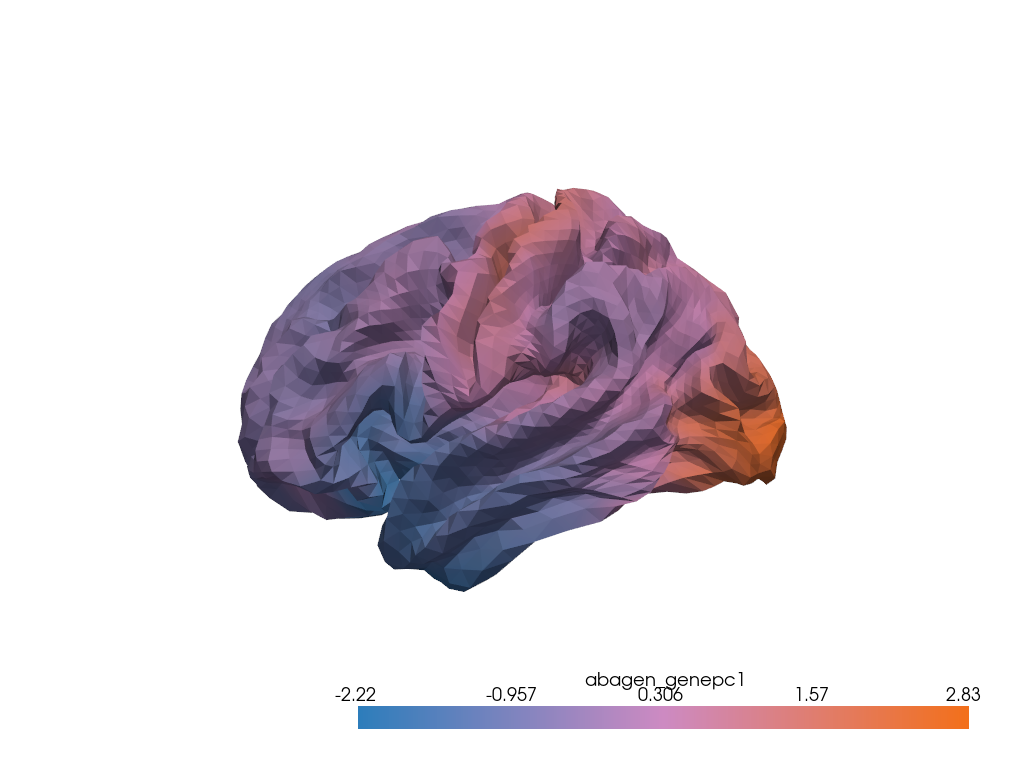

In [156]:
import pyvista as pv

pl = pv.Plotter()

pl.add_mesh(src_pvdata.rotate_z(180), scalars='abagen_genepc1', cmap = bpr)
pl.camera_position='yz'
pl.show(jupyter_backend='static')

In [157]:
full_map = np.zeros(src_pvdata.n_points)
full_map[kv[:,0].astype(int)] = mapvals[kv[:,0].astype(int)]
full_map[uv[:,0].astype(int)] = y1

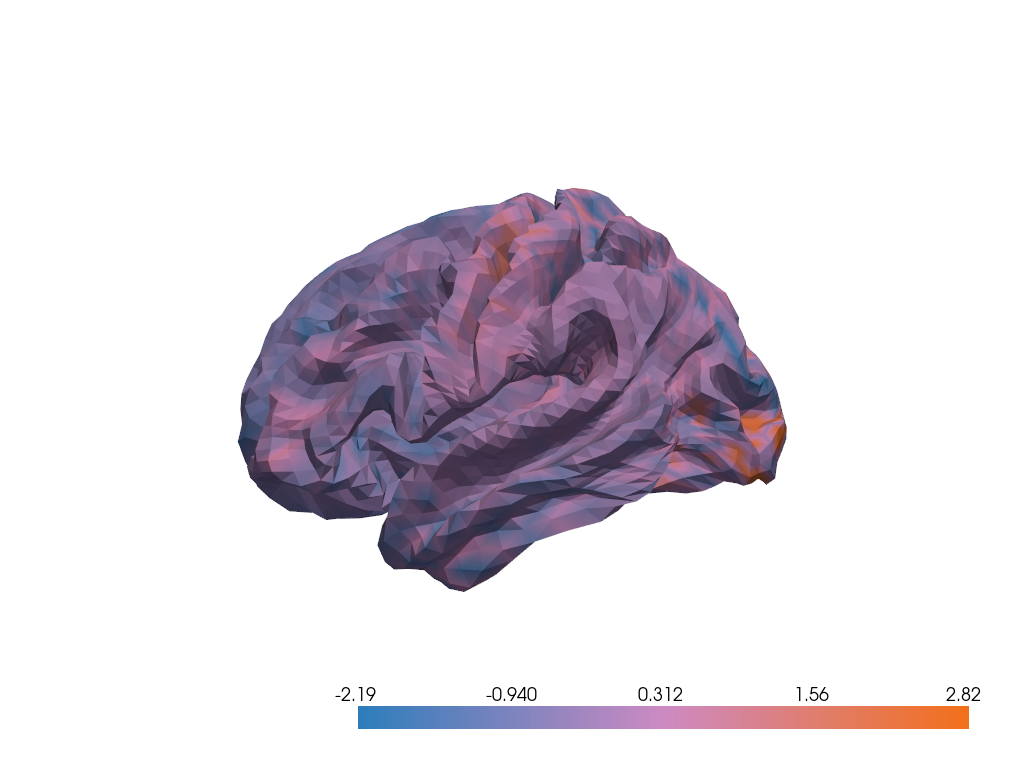

In [158]:
import pyvista as pv

pl = pv.Plotter()

pl.add_mesh(src_pvdata.rotate_z(180), scalars=full_map, cmap = bpr)
pl.camera_position='yz'
pl.show(jupyter_backend='static')

In [ ]:
# Best kriging model

def _make_a_kriger(X0, Y0, x1, yk1=None, Yk0=None, model = 'exponential', method='Ordinary', timeit=True, plotit=False, filename=None):
    '''
    exporting variogram fitted with gkstat to gstools

    for Ordinary and Regression kriging
    '''

    #if timeit: t1=time.time()

    binned_vario = skg.Variogram(coordinates = X0, \
             values = Y0, \
             model = model, \
             n_lags = 25, bin_func = 'even', use_nugget = True)
    
    x, y = binned_vario.get_empirical(bin_center=True)

    bounds = {3: ([0.00001]*3, [np.nanmax(x), np.nanmax(y), np.nanmax(y)/25]),
          4: ([0.00001]*4, [np.nanmax(x), np.nanmax(y), np.nanmax(y)/25, 1])
         }

    #bounds = (0.00001, [np.nanmax(x), np.nanmax(y), np.nanmax(y)/10])

    if model in ['stable', 'matern']:
        binned_vario.fit(force=True, method = 'trf', p0=bounds[4][1], maxfev=1000)
    
    else:
        binned_vario.fit(force=True, method = 'trf', p0=bounds[3][1], maxfev=1000)
        
    

    if plotit:
        import matplotlib.pyplot as plt
    
        plt.scatter(x, y, color = 'k')
        
        plt.plot(binned_vario.data()[0], binned_vario.data()[1], color = 'r')
        plt.axhline(binned_vario.cof[1], color = 'r', linestyle = 'dotted')
        plt.axvline(binned_vario.cof[0], color = 'r', linestyle = 'dotted')
        plt.ylabel('semivariance')
        plt.xlabel('distance')
        plt.savefig(filename)
        
    fitted_vario = binned_vario.to_gstools()
    
    if method == 'Ordinary':
        kriger = OrdinaryKriging3D(x=X0[:,0], y=X0[:,1], z=X0[:,2], val = Y0,\
                                   variogram_model = fitted_vario, \
                                exact_values = True)

    elif method == 'Universal':
        kriger = UniversalKriging3D(x=X0[:,0], y=X0[:,1], z=X0[:,2], val = Y0,\
                                   variogram_model = fitted_vario, \
                                exact_values = True)

    if method == 'Regression':
        
        kriger = RegressionKriging(variogram_model = fitted_vario, \
                                   coordinates_type = 'euclidean', \
                                   method = 'ordinary3d', exact_values=True)
        kriger.fit(p=Yk0.T, x=X0, y=Y0)
        
    return kriger